In [1]:
# Cell 1 — Import
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
model = tf.keras.models.load_model("outputs/models/best_model.keras")
class_names = ['cat', 'dog']

In [10]:
def predict_image(img_path, show=True):
    img = Image.open(img_path).convert('RGB')
    img_resized = img.resize((224, 224))
    arr = np.array(img_resized, dtype=np.float32) / 255.0
    arr = np.expand_dims(arr, axis=0)  

    prob = model.predict(arr, verbose=0)[0][0] 

    label = 'dog' if prob > 0.5 else 'cat'
    conf  = prob if prob > 0.5 else 1 - prob

    if show:
        plt.figure(figsize=(4, 4))
        plt.imshow(img)
        plt.title(f"{label.upper()}\nconfidence: {conf:.2%}",
                  fontsize=13,
                  color='green' if conf > 0.85 else 'orange')
        plt.axis('off')
        plt.tight_layout()
        plt.show()

    return label, conf

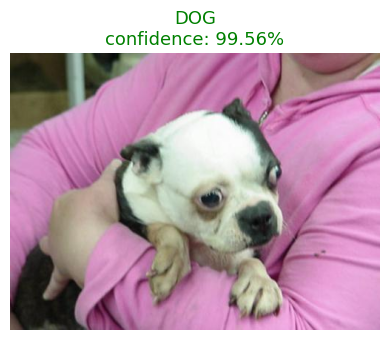

ผลลัพธ์ : dog
ความมั่นใจ : 99.56%


In [12]:
img_path = "../data/test/dog/2052.jpg"

label, conf = predict_image(img_path)
print(f"ผลลัพธ์ : {label}")
print(f"ความมั่นใจ : {conf:.2%}")

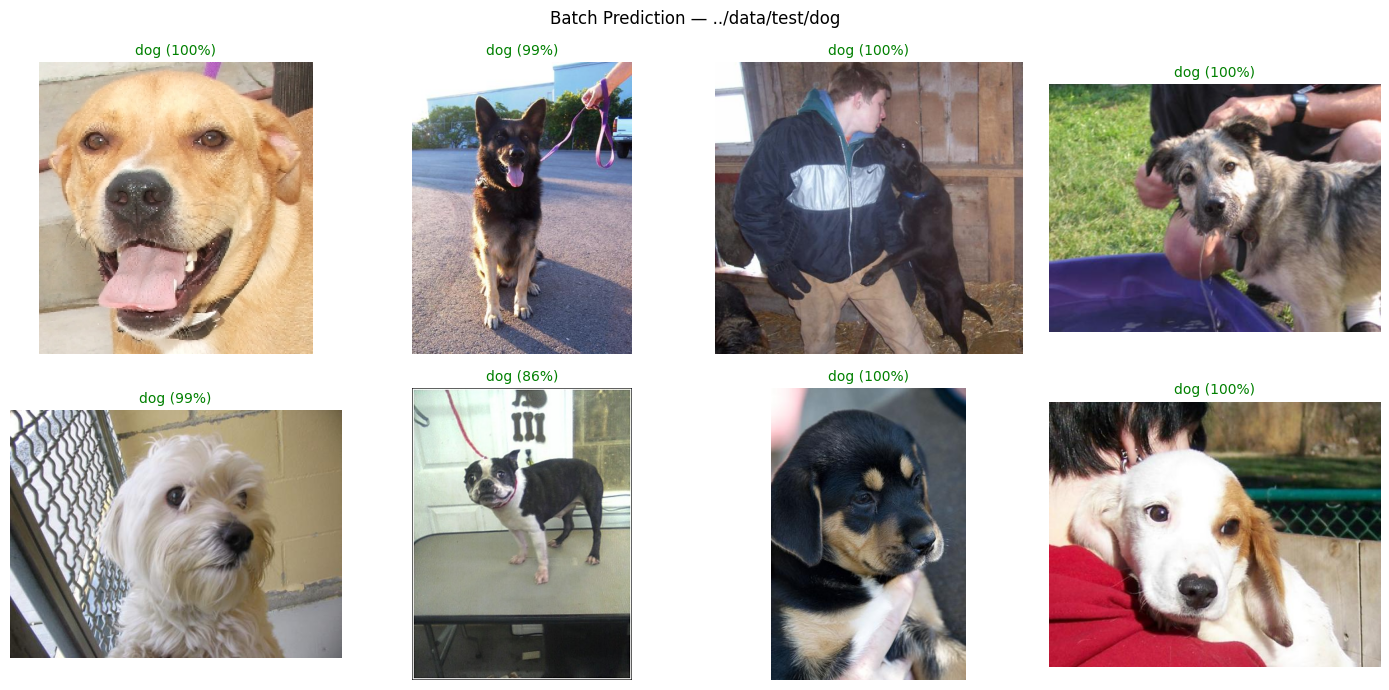

In [19]:
import os

def predict_batch(folder_path, n=8):

    files = [f for f in os.listdir(folder_path)
             if f.lower().endswith(('.jpg', '.jpeg', '.png'))][:n]

    cols = 4
    rows = -(-len(files) // cols) 
    fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 3.5))
    axes = axes.flatten()

    for i, fname in enumerate(files):
        fpath = os.path.join(folder_path, fname)
        img   = Image.open(fpath).convert('RGB')
        arr   = np.array(img.resize((224, 224)), dtype=np.float32) / 255.0
        prob  = model.predict(np.expand_dims(arr, 0), verbose=0)[0][0]

        label = 'dog' if prob > 0.5 else 'cat'
        conf  = prob if prob > 0.5 else 1 - prob

        axes[i].imshow(img)
        axes[i].set_title(f"{label} ({conf:.0%})",
                          fontsize=10,
                          color='green' if conf > 0.85 else 'orange')
        axes[i].axis('off')

    for j in range(len(files), len(axes)):
        axes[j].axis('off')

    plt.suptitle(f"Batch Prediction — {folder_path}", fontsize=12)
    plt.tight_layout()
    plt.savefig("../outputs/predictions/batch2_result.png")
    plt.show()

os.makedirs("../outputs/predictions", exist_ok=True)
predict_batch("../data/test/dog", n=8)